# News Article Clustering — Analysis Notebook

## 1. Problem Statement
This notebook explores whether **groups of similar news articles** emerge naturally
from a set of engineered numeric features, using **unsupervised clustering**
(K-Means and Agglomerative Hierarchical Clustering).

Unlike the earlier classification project (which *predicted* the known `Category`
label), clustering here is **not told the categories at all** — it only sees
numeric features derived from each title's text, and groups similar titles together
on its own. The known `Category` labels are used only *after* clustering, to help
interpret what each discovered cluster might represent.

## 2. The Feature-Engineered Dataset
The raw dataset (`data/News_Classification_Labeling.xlsx`) has just three columns:
`URL`, `Title`, `Category` — 5000 news headlines across 6 categories
(Business, Markets, Politics, Technology, Health, Energy).

Stage 1 of this project (`src/feature_engineering.py`) builds 7 numeric structural
features directly from the `Title` text:

| Feature | What it measures |
|---|---|
| `title_len` | Character length of the title |
| `num_digits_count` | Count of digit characters |
| `question_mark_count` | Count of `?` characters |
| `punctuation_count` | Count of punctuation characters |
| `sentiment_score` | VADER sentiment (-1 negative to +1 positive) |
| `poi_count` | Count of multi-word capitalized phrases (proxy for named entities) |
| `has_location` | 1 if a country/city keyword appears in the title |

In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), "..", "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from data_loader import load_dataset
from feature_engineering import add_engineered_features, ENGINEERED_FEATURE_COLUMNS
from preprocessing import select_clustering_features, scale_features
from evaluation import evaluate_k_range, select_best_k
from kmeans_clustering import run_kmeans
from hierarchical_clustering import compute_linkage, select_threshold, assign_clusters
from analysis import cluster_sizes, cluster_category_breakdown
from scipy.cluster.hierarchy import dendrogram
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)

## 3. Data Inspection

In [2]:
df = load_dataset("../data/News_Classification_Labeling.xlsx")
print(df.shape)
df.head()

[data_loader] Note: 1 row(s) have missing Category (kept for clustering, excluded from category analysis).
(5000, 3)


,URL,Title,Category
0,https://asiatimes.com/2025/10/vietnam-airlines...,Vietnam Airlines data leak exposes a crisis of...,Technology
1,https://asiatimes.com/2025/10/doj-seizes-15-bi...,DOJ seizes $15 billion bitcoin in SE Asia cryp...,Markets
2,https://www.fool.com/investing/2025/10/15/too-...,Think It's Too Late to Buy IonQ? Here's the 1 ...,Markets
3,https://www.fool.com/investing/2025/10/15/inte...,Intel's Crucial Panther Lake Chips Start Produ...,Technology
4,https://www.fool.com/investing/2025/10/15/3-ro...,3 Robotics Stocks to Buy in October,Markets


In [3]:
df["Category"].value_counts()

Category
Business      1896
Markets       1518
Politics       862
Technology     452
Health         144
Energy         127
Name: count, dtype: int64

## 4. Building the Engineered Features

In [4]:
df = add_engineered_features(df)
df[["Title"] + ENGINEERED_FEATURE_COLUMNS].head()

,Title,title_len,num_digits_count,question_mark_count,punctuation_count,sentiment_score,poi_count,has_location
0,Vietnam Airlines data leak exposes a crisis of...,59,0,0,0,-0.7906,1,1
1,DOJ seizes $15 billion bitcoin in SE Asia cryp...,58,2,0,1,-0.5719,0,1
2,Think It's Too Late to Buy IonQ? Here's the 1 ...,75,1,1,4,0.0000,4,0
3,Intel's Crucial Panther Lake Chips Start Produ...,51,0,0,1,0.0000,1,0
4,3 Robotics Stocks to Buy in October,35,1,0,0,0.0000,1,0


In [5]:
df[ENGINEERED_FEATURE_COLUMNS].describe()

,title_len,num_digits_count,question_mark_count,punctuation_count,sentiment_score,poi_count,has_location
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,74.516400,1.597600,0.018400,1.637400,0.083076,1.353600,0.374000
std,24.854683,2.645652,0.134406,1.779144,0.320529,1.267158,0.483912
min,16.000000,0.000000,0.000000,0.000000,-0.910000,0.000000,0.000000
25%,59.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,71.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
75%,86.000000,2.000000,0.000000,2.000000,0.318200,2.000000,1.000000
max,275.000000,23.000000,1.000000,11.000000,0.924600,7.000000,1.000000


## 5. Why `Category` Is Excluded From Clustering
Clustering is **unsupervised** — the entire point is to discover structure
*without* being told the answer. If `Category` were included as an input feature,
the clusters would just trivially reproduce the known labels, which defeats the
purpose and isn't really "discovery" at all.

So: `URL` and `Title` are identifiers/raw text (not numeric features), and
`Category` is the label. All three are excluded from the clustering input.
`Category` is kept aside and reattached only *after* clustering, purely to help
interpret the clusters (Section 19).

## 6. Scaling
The 7 engineered features have very different ranges — `title_len` is roughly
16–275, `num_digits_count` is roughly 0–23, while `sentiment_score` is bounded
[-1, 1] and `has_location` is 0/1. Both K-Means and Ward-linkage hierarchical
clustering compute **Euclidean distances** between points. Without scaling,
`title_len` alone would dominate every distance calculation, and the other
6 features would barely matter. `StandardScaler` puts every feature on a
comparable scale (mean 0, std 1).

In [6]:
X = select_clustering_features(df)
X_scaled, scaler = scale_features(X)
print("Feature matrix shape:", X_scaled.shape)

Feature matrix shape: (5000, 7)


## 7. K-Means Clustering — Introduction
K-Means partitions points into K clusters by iteratively:
1. Assigning each point to its nearest cluster center (centroid)
2. Recomputing each centroid as the mean of its assigned points

...until the assignments stop changing. It requires choosing K in advance.

## 8. Candidate K Values
We test K = 2 through K = 10.

## 9. Silhouette Score
For each point, Silhouette Score compares (a) how close it is to other points in
its **own** cluster vs. (b) how close it is to the **nearest other** cluster.
It ranges from -1 to +1 — higher means better-defined, well-separated clusters.
Averaged over all points, it gives one score per K. This is used as the single,
primary metric for choosing K (rather than combining several internal metrics).

In [7]:
scores_df = evaluate_k_range(X_scaled, range(2, 11))
scores_df

[evaluation] K=2: Silhouette Score = 0.2735


[evaluation] K=3: Silhouette Score = 0.2174


[evaluation] K=4: Silhouette Score = 0.2384


[evaluation] K=5: Silhouette Score = 0.2496


[evaluation] K=6: Silhouette Score = 0.2176


[evaluation] K=7: Silhouette Score = 0.2029


[evaluation] K=8: Silhouette Score = 0.2073


[evaluation] K=9: Silhouette Score = 0.2152


[evaluation] K=10: Silhouette Score = 0.2192


,K,Silhouette_Score
0,2,0.2735
1,3,0.2174
2,4,0.2384
3,5,0.2496
4,6,0.2176
5,7,0.2029
6,8,0.2073
7,9,0.2152
8,10,0.2192


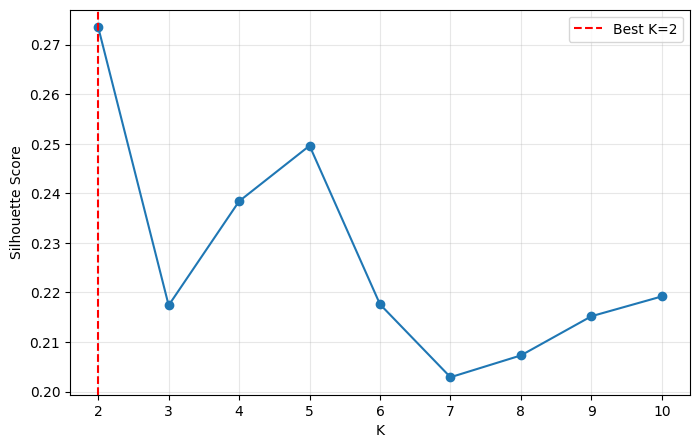

In [8]:
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(scores_df["K"], scores_df["Silhouette_Score"], marker="o")
best_k_preview = select_best_k(scores_df)
ax.axvline(best_k_preview, color="red", linestyle="--", label=f"Best K={best_k_preview}")
ax.set_xlabel("K"); ax.set_ylabel("Silhouette Score"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 10. Best K Selection

In [9]:
best_k = select_best_k(scores_df)
print(f"Best K: {best_k} (Silhouette Score = {scores_df['Silhouette_Score'].max():.4f})")

Best K: 2 (Silhouette Score = 0.2735)


**Note:** K=2 gives the single highest Silhouette Score, but the curve also
has a local peak at K=5. A K around 5 may be more *practically* interesting since
it's closer to the 6 real news categories — this trade-off (mathematically "cleanest"
split vs. more granular groups) is discussed further in Section 20.

## 11. Final K-Means Clustering

In [10]:
kmeans_model, kmeans_labels = run_kmeans(X_scaled, best_k)
kmeans_sizes = cluster_sizes(kmeans_labels)
kmeans_sizes

,Cluster,Size
0,0,3730
1,1,1270


## 12. K-Means Visualization
The feature space is 7-dimensional, so PCA is used **only to project down to 2D
for plotting**. Clustering itself was performed on the full 7D scaled feature
space, not on these PCA components.

2D PCA explains 44.2% of total variance


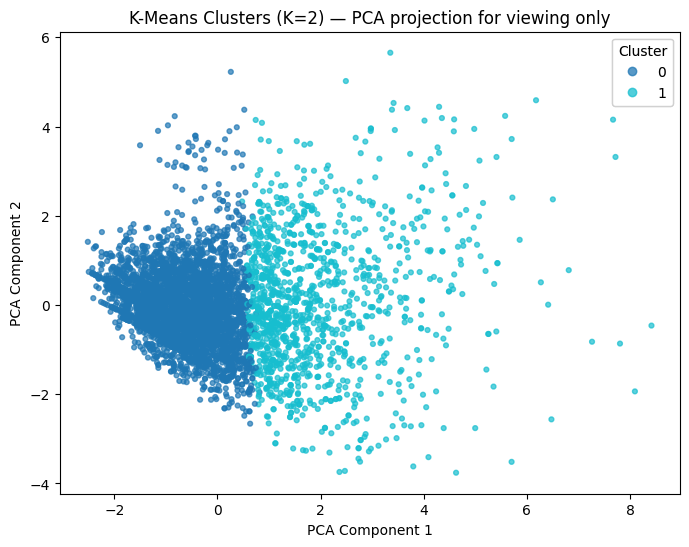

In [11]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"2D PCA explains {pca.explained_variance_ratio_.sum():.1%} of total variance")

fig, ax = plt.subplots(figsize=(8,6))
scatter = ax.scatter(X_pca[:,0], X_pca[:,1], c=kmeans_labels, cmap="tab10", s=12, alpha=0.7)
ax.set_xlabel("PCA Component 1"); ax.set_ylabel("PCA Component 2")
ax.set_title(f"K-Means Clusters (K={best_k}) — PCA projection for viewing only")
legend1 = ax.legend(*scatter.legend_elements(), title="Cluster")
ax.add_artist(legend1)
plt.show()

## 13. Hierarchical Clustering — Introduction
Agglomerative (bottom-up) hierarchical clustering: every point starts as its own
cluster; at each step the two closest clusters are merged; this repeats until
everything is one cluster, forming a tree.

## 14. The Bottom-Up (Agglomerative) Approach
Individual points → merge closest/similar clusters → larger clusters →
one hierarchy/tree. **Ward linkage** is used, which merges the pair of clusters
that leads to the smallest increase in total within-cluster variance — it tends
to produce compact, evenly-sized clusters, similar in spirit to K-Means.
`Category` is not used as an input feature here either.

In [12]:
Z = compute_linkage(X_scaled)
print("Linkage matrix shape:", Z.shape)

Linkage matrix shape: (4999, 4)


## 15. Dendrogram

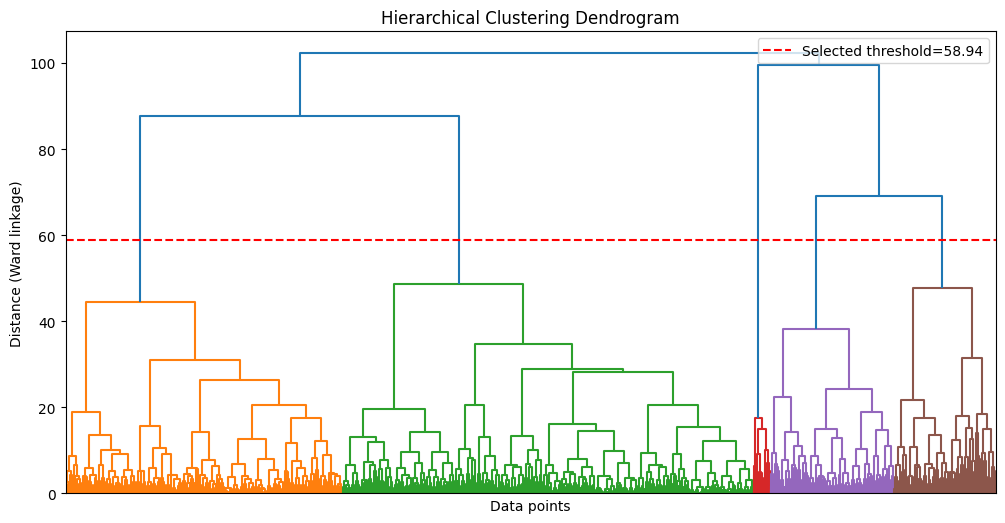

In [13]:
threshold = select_threshold(Z)

fig, ax = plt.subplots(figsize=(12,6))
dendrogram(Z, no_labels=True, color_threshold=threshold, ax=ax)
ax.axhline(threshold, color="red", linestyle="--", label=f"Selected threshold={threshold:.2f}")
ax.set_xlabel("Data points"); ax.set_ylabel("Distance (Ward linkage)")
ax.set_title("Hierarchical Clustering Dendrogram")
ax.legend()
plt.show()

## 16. Threshold Selection
Cutting the dendrogram at a given distance produces a specific number of clusters.
Rather than hardcoding an arbitrary distance, a **largest-gap heuristic** is used:
look at the last 15 merge distances (the highest, most significant merges near the
top of the tree) and find the biggest jump between two consecutive merge distances.
Everything below that gap is "genuinely close"; everything above is "forcing unlike
clusters together". The threshold is set at the midpoint of that gap.

In [14]:
print(f"Selected threshold: {threshold:.4f}")

Selected threshold: 58.9427


## 17. Final Hierarchical Clusters

In [15]:
hier_labels = assign_clusters(Z, threshold)
print(f"Resulting number of clusters: {len(set(hier_labels))}")

Resulting number of clusters: 5


## 18. Hierarchical Cluster Sizes

In [16]:
hier_sizes = cluster_sizes(hier_labels)
hier_sizes

,Cluster,Size
0,1,1487
1,2,2212
2,3,92
3,4,664
4,5,545


## 19. Optional Category-Based Interpretation
**Important:** `Category` was never used to build these clusters. This section only
checks, after the fact, whether the discovered clusters happen to align with any
known category — purely for human interpretation.

In [17]:
kmeans_out = df[["Title", "Category"]].copy()
kmeans_out["Cluster"] = kmeans_labels
category_breakdown = cluster_category_breakdown(kmeans_out, "Cluster")
category_breakdown

Category,Cluster,Business,Energy,Health,Markets,Politics,Technology
0,0,36.6,2.5,2.7,29.0,20.3,8.9
1,1,41.8,2.8,3.3,34.3,8.3,9.5


## 20. K-Means vs. Hierarchical — Comparison

- **Number of clusters:** K-Means settled on the mathematically "cleanest" split
  (K=2, by Silhouette Score), which mostly separates titles by overall
  length/punctuation/complexity rather than topic. Hierarchical clustering, cut at
  the largest-gap threshold, produced 5 clusters of very different sizes (from ~90
  to ~2200 rows).
- **Cluster sizes:** K-Means gives two fairly large, comparably-sized groups.
  Hierarchical produces a mix — a couple of large groups and a few small, tighter
  ones — which is typical of Ward-linkage hierarchical clustering on data without
  sharply separated natural groups.
- **Do similar groups appear?** Broadly yes — both methods separate on structural
  writing style (title length, punctuation density, sentiment) since those are the
  only signals available. Neither recovers the 6 news categories, which is expected
  (see caveat below).
- **Which is more useful here?** Hierarchical clustering's dendrogram is more
  informative for this dataset since it shows *how* groups relate at different
  granularities, rather than committing to one flat K. K-Means is faster and gives
  a single clean answer, but K=2 is a fairly coarse split for 5000 varied headlines.
- **Limitations:** The clustering input here is only 7 structural/stylistic
  features of the *title text* (not its topical content), so it's better at
  grouping titles by "how they're written" (long/short, question-style, sentiment)
  than "what they're about". This is expected and not a flaw in the clustering
  method itself — it's a limitation of the feature set available.

## 21. Conclusion
This notebook engineered 7 structural features from raw headline text and used
them for unsupervised clustering with two different algorithms. K-Means found
K=2 to be the statistically best split by Silhouette Score; hierarchical
clustering, using a data-driven threshold, found 5 clusters at varying
granularities. **Neither clustering result should be read as recovering the true
news categories** — Category was withheld from clustering entirely and is only
used afterward for interpretation. The clusters instead reflect structural/stylistic
patterns in how the titles are written.